In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format
pd.set_option("display.max_colwidth", 60)

df = pd.read_csv("../data/processed/sales_analysis_ready.csv",
                 parse_dates=["order_date", "ship_date"],
                 dtype={"postal_code": str})
print(df.shape)
print(round(df["sales"].sum(), 2), round(df["profit"].sum(), 2))

(9993, 27)
2296919.49 286409.08


In [2]:
print("Names:", df["product_name"].nunique(),
      "| IDs:", df["product_id"].nunique(),
      "| keys:", df["product_key"].nunique())

ids_per_name = df.groupby("product_name")["product_id"].nunique()
multi_names = ids_per_name[ids_per_name > 1].index
print("Names with more than one Product ID:", len(multi_names))

multi = (df[df["product_name"].isin(multi_names)]
           .groupby("product_name")
           .agg(ids=("product_id", "nunique"),
                keys=("product_key", "nunique"),
                lines=("row_id", "count"),
                categories=("category", "nunique"),
                sub_categories=("sub_category", "nunique"),
                sales=("sales", "sum"),
                profit=("profit", "sum"))
           .sort_values("lines", ascending=False))
print("Lines involved:", multi["lines"].sum())
multi

Names: 1850 | IDs: 1862 | keys: 1894
Names with more than one Product ID: 16
Lines involved: 314


,ids,keys,lines,categories,sub_categories,sales,profit
product_name,,,,,,,
Staple envelope,9,9,48,1,1,"1,686.81",751.63
Easy-staple paper,8,8,46,1,1,"2,504.19","1,096.03"
Staples,10,10,46,1,1,755.47,292.20
Avery Non-Stick Binders,2,2,20,1,1,217.32,43.55
Staples in misc. colors,7,7,19,1,1,478.81,124.05
Staple remover,3,3,18,1,1,263.09,24.07
KI Adjustable-Height Table,2,2,18,1,1,"4,552.64",-248.48
Storex Dura Pro Binders,2,2,17,1,1,278.59,50.55
Staple-based wall hangings,2,2,16,1,1,422.29,121.99


In [3]:
example_name = multi.index[0]
print(example_name)
(df[df["product_name"] == example_name]
   .groupby(["product_id", "product_key"])
   .agg(lines=("row_id", "count"), sales=("sales", "sum"), profit=("profit", "sum"))
   .reset_index())

Staple envelope


,product_id,product_key,lines,sales,profit
0,OFF-EN-10001028,865,2,100.63,42.41
1,OFF-EN-10001099,866,5,160.39,65.33
2,OFF-EN-10001415,871,5,54.68,23.99
3,OFF-EN-10001539,877,7,196.06,88.85
4,OFF-EN-10001990,879,6,130.64,61.40
5,OFF-EN-10002621,886,5,78.24,34.23
6,OFF-EN-10003134,895,7,247.62,107.46
7,OFF-EN-10003286,897,7,284.83,131.24
8,OFF-EN-10004773,911,4,433.72,196.72


In [4]:
by_name = df.groupby("product_name").agg(sales=("sales", "sum"), profit=("profit", "sum"))
by_key = (df.groupby("product_key")
            .agg(name=("product_name", "first"), sales=("sales", "sum"), profit=("profit", "sum")))

print("Products by name:", len(by_name), "| by key:", len(by_key))
print("Loss-making by name:", (by_name["profit"] < 0).sum(),
      "| by key:", (by_key["profit"] < 0).sum())

same_top = set(by_name.nlargest(20, "sales").index) & set(by_key.nlargest(20, "sales")["name"])
same_loss = set(by_name.nsmallest(20, "profit").index) & set(by_key.nsmallest(20, "profit")["name"])
print("Same names in the top 20 by sales:", len(same_top), "of 20")
print("Same names in the 20 biggest losers:", len(same_loss), "of 20")

Products by name: 1850 | by key: 1894
Loss-making by name: 301 | by key: 306
Same names in the top 20 by sales: 20 of 20
Same names in the 20 biggest losers: 20 of 20


In [5]:
tiny = by_key[(by_key["profit"] < 0) & (by_key["profit"] > -0.005)]
print("Products with a negative profit smaller than half a cent:", len(tiny))
print("By key, loss-making (half-cent tolerance): ", (by_key["profit"] < -0.005).sum())
print("By name, loss-making (half-cent tolerance):", (by_name["profit"] < -0.005).sum())
tiny

Products with a negative profit smaller than half a cent: 2
By key, loss-making (half-cent tolerance):  304
By name, loss-making (half-cent tolerance): 299


,name,sales,profit
product_key,,,
125,Global Super Steno Chair,"2,389.90",-0.00
768,"Avery Trapezoid Extra Heavy Duty 4"" Binders",314.55,-0.00


In [6]:
PRODUCT_COL = "product_name"   # change to "product_key" to do everything the other way

group_cols = ["product_name"] if PRODUCT_COL == "product_name" else ["product_key", "product_name"]

products = (df.groupby(group_cols + ["category", "sub_category"])
              .agg(sales=("sales", "sum"),
                   profit=("profit", "sum"),
                   units=("quantity", "sum"),
                   lines=("row_id", "count"),
                   avg_discount=("discount", "mean"),
                   pct_lines_30plus=("discount", lambda s: (s >= 0.30).mean() * 100))
              .reset_index())
products["margin_pct"] = products["profit"] / products["sales"] * 100

print("Counting by:", PRODUCT_COL)
print("Products:", len(products), "| duplicates:", products[group_cols].duplicated().sum())
print("Sales:", round(products["sales"].sum(), 2), "| Profit:", round(products["profit"].sum(), 2))

Counting by: product_name
Products: 1850 | duplicates: 0
Sales: 2296919.49 | Profit: 286409.08


In [7]:
sub = (df.groupby(["category", "sub_category"])
         .agg(sales=("sales", "sum"),
              profit=("profit", "sum"),
              units=("quantity", "sum"),
              lines=("row_id", "count"),
              avg_discount=("discount", "mean"),
              pct_lines_30plus=("discount", lambda s: (s >= 0.30).mean() * 100))
         .reset_index())
sub["margin_pct"] = sub["profit"] / sub["sales"] * 100
sub["pct_of_sales"] = sub["sales"] / sub["sales"].sum() * 100
sub["pct_of_profit"] = sub["profit"] / sub["profit"].sum() * 100
sub.sort_values("profit", ascending=False).reset_index(drop=True)

,category,sub_category,sales,profit,units,lines,avg_discount,pct_lines_30plus,margin_pct,pct_of_sales,pct_of_profit
0,Technology,Copiers,"149,528.03","55,617.82",234,68,0.16,13.24,37.20,6.51,19.42
1,Technology,Phones,"330,007.05","44,515.73",3289,889,0.15,12.26,13.49,14.37,15.54
2,Technology,Accessories,"167,380.32","41,936.64",2976,775,0.08,0.00,25.05,7.29,14.64
3,Office Supplies,Paper,"78,479.21","34,053.57",5178,1370,0.07,0.00,43.39,3.42,11.89
4,Office Supplies,Binders,"203,412.73","30,221.76",5974,1523,0.37,40.25,14.86,8.86,10.55
5,Furniture,Chairs,"328,167.73","26,602.23",2354,616,0.17,25.49,8.11,14.29,9.29
6,Office Supplies,Storage,"223,843.61","21,278.83",3158,846,0.07,0.00,9.51,9.75,7.43
7,Office Supplies,Appliances,"107,532.16","18,138.01",1729,466,0.17,14.38,16.87,4.68,6.33
8,Furniture,Furnishings,"91,705.16","13,059.14",3563,957,0.14,14.42,14.24,3.99,4.56
9,Office Supplies,Envelopes,"16,476.40","6,964.18",906,254,0.08,0.00,42.27,0.72,2.43


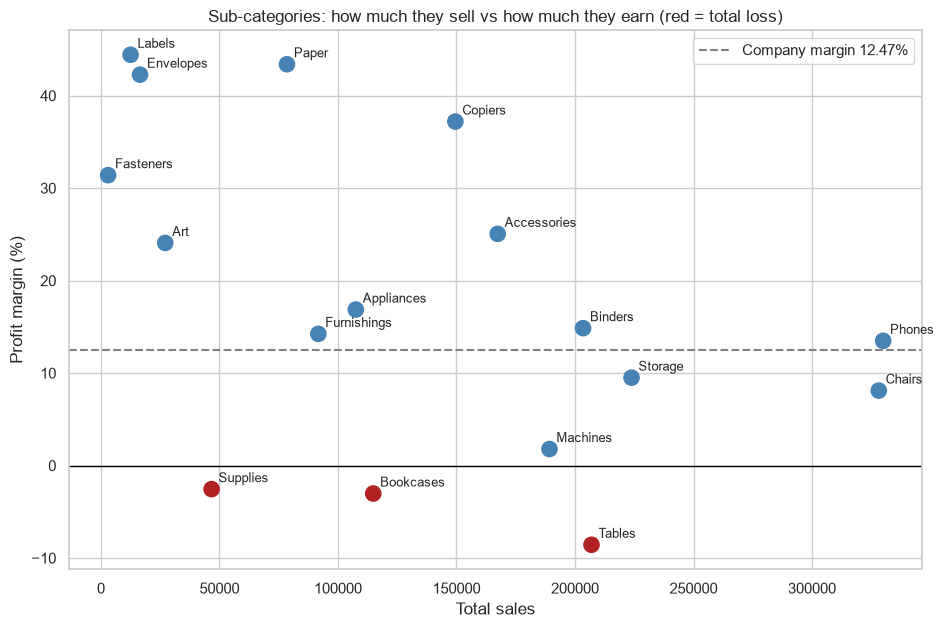

In [8]:
overall_margin = df["profit"].sum() / df["sales"].sum() * 100

fig, ax = plt.subplots(figsize=(11, 7))
colors = sub["profit"].apply(lambda p: "firebrick" if p < 0 else "steelblue")
ax.scatter(sub["sales"], sub["margin_pct"], s=120, c=colors)
for _, r in sub.iterrows():
    ax.annotate(r["sub_category"], (r["sales"], r["margin_pct"]),
                xytext=(5, 5), textcoords="offset points", fontsize=9)
ax.axhline(0, color="black", linewidth=1)
ax.axhline(overall_margin, color="gray", linestyle="--",
           label=f"Company margin {overall_margin:.2f}%")
ax.set_xlabel("Total sales")
ax.set_ylabel("Profit margin (%)")
ax.set_title("Sub-categories: how much they sell vs how much they earn (red = total loss)")
ax.legend()
plt.savefig("../images/product_01_subcategory_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

136 products (7.4% of all products) make 50% of the sales
420 products (22.7% of all products) make 80% of the sales


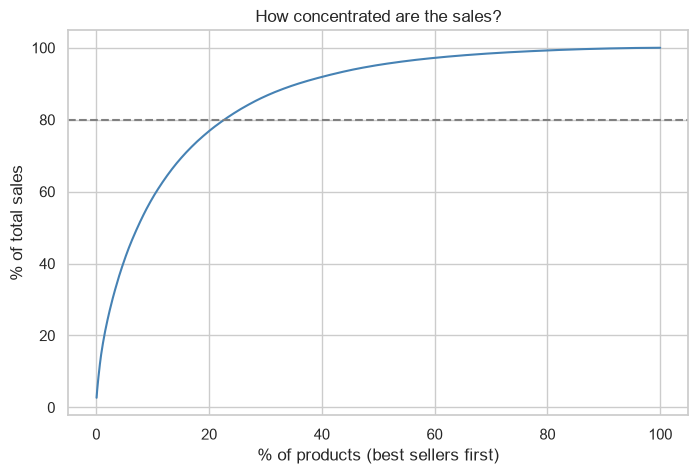

In [9]:
def products_for_share(series, share):
    s = series.sort_values(ascending=False)
    cum = s.cumsum() / s.sum()
    return int((cum < share).sum() + 1)

n = len(products)
for share in [0.5, 0.8]:
    k = products_for_share(products["sales"], share)
    print(f"{k} products ({k / n * 100:.1f}% of all products) make {share * 100:.0f}% of the sales")

s = products["sales"].sort_values(ascending=False).reset_index(drop=True)
x = (s.index + 1) / n * 100
y = s.cumsum() / s.sum() * 100

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, y, color="steelblue")
ax.axhline(80, color="gray", linestyle="--")
ax.set_xlabel("% of products (best sellers first)")
ax.set_ylabel("% of total sales")
ax.set_title("How concentrated are the sales?")
plt.savefig("../images/product_02_sales_concentration.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
products["status"] = np.where(products["profit"] < -0.005, "Loss-making", "Profit or break-even")

lines = df.merge(products[group_cols + ["status"]], on=group_cols, how="left")
print("Lines:", len(lines), "| lines without a status:", lines["status"].isna().sum())

status_tbl = (lines.groupby("status")
                .agg(lines=("row_id", "count"),
                     sales=("sales", "sum"),
                     profit=("profit", "sum"),
                     avg_discount=("discount", "mean"),
                     pct_lines_30plus=("discount", lambda s: (s >= 0.30).mean() * 100)))
status_tbl["products"] = products.groupby("status")[PRODUCT_COL].count()
status_tbl["margin_pct"] = status_tbl["profit"] / status_tbl["sales"] * 100
status_tbl["pct_of_sales"] = status_tbl["sales"] / status_tbl["sales"].sum() * 100
status_tbl

Lines: 9993 | lines without a status: 0


,lines,sales,profit,avg_discount,pct_lines_30plus,products,margin_pct,pct_of_sales
status,,,,,,,,
Loss-making,1577,"550,382.94","-77,068.38",0.27,36.72,299,-14.00,23.96
Profit or break-even,8416,"1,746,536.55","363,477.46",0.13,9.66,1551,20.81,76.04


In [11]:
show = group_cols + ["sub_category", "lines", "sales", "profit", "margin_pct", "pct_lines_30plus"]

print("TOP 10 by SALES")
display(products.nlargest(10, "sales")[show].reset_index(drop=True))

print("TOP 10 by PROFIT")
display(products.nlargest(10, "profit")[show].reset_index(drop=True))

print("BOTTOM 10 by PROFIT (biggest losses)")
display(products.nsmallest(10, "profit")[show].reset_index(drop=True))

top20 = products.nlargest(20, "sales")
print("Of the 20 best sellers:", (top20["profit"] < -0.005).sum(), "lose money;",
      (top20["margin_pct"] < overall_margin).sum(), "have a margin below the company margin")

TOP 10 by SALES


,product_name,sub_category,lines,sales,profit,margin_pct,pct_lines_30plus
0,Canon imageCLASS 2200 Advanced Copier,Copiers,5,"61,599.82","25,199.93",40.91,20.00
1,Fellowes PB500 Electric Punch Plastic Comb Binding Machi...,Binders,10,"27,453.38","7,753.04",28.24,20.00
2,Cisco TelePresence System EX90 Videoconferencing Unit,Machines,1,"22,638.48","-1,811.08",-8.00,100.00
3,HON 5400 Series Task Chairs for Big and Tall,Chairs,8,"21,870.58",0.00,0.00,37.50
4,GBC DocuBind TL300 Electric Binding System,Binders,11,"19,823.48","2,233.51",11.27,36.36
5,GBC Ibimaster 500 Manual ProClick Binding System,Binders,9,"19,024.50",760.98,4.00,66.67
6,Hewlett Packard LaserJet 3310 Copier,Copiers,8,"18,839.69","6,983.88",37.07,25.00
7,"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",Machines,3,"18,374.90","4,094.98",22.29,33.33
8,GBC DocuBind P400 Electric Binding System,Binders,6,"17,965.07","-1,878.17",-10.45,50.00
9,High Speed Automatic Electric Letter Opener,Supplies,3,"17,030.31",-262.00,-1.54,0.00


TOP 10 by PROFIT


,product_name,sub_category,lines,sales,profit,margin_pct,pct_lines_30plus
0,Canon imageCLASS 2200 Advanced Copier,Copiers,5,"61,599.82","25,199.93",40.91,20.00
1,Fellowes PB500 Electric Punch Plastic Comb Binding Machi...,Binders,10,"27,453.38","7,753.04",28.24,20.00
2,Hewlett Packard LaserJet 3310 Copier,Copiers,8,"18,839.69","6,983.88",37.07,25.00
3,Canon PC1060 Personal Laser Copier,Copiers,4,"11,619.83","4,570.93",39.34,0.00
4,"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",Machines,3,"18,374.90","4,094.98",22.29,33.33
5,Ativa V4110MDD Micro-Cut Shredder,Machines,2,"7,699.89","3,772.95",49.00,0.00
6,"3D Systems Cube Printer, 2nd Generation, Magenta",Machines,2,"14,299.89","3,717.97",26.00,0.00
7,Plantronics Savi W720 Multi-Device Wireless Headset System,Accessories,7,"9,367.29","3,696.28",39.46,0.00
8,Ibico EPK-21 Electric Binding System,Binders,3,"15,875.92","3,345.28",21.07,33.33
9,Zebra ZM400 Thermal Label Printer,Machines,2,"6,965.70","3,343.54",48.00,0.00


BOTTOM 10 by PROFIT (biggest losses)


,product_name,sub_category,lines,sales,profit,margin_pct,pct_lines_30plus
0,Cubify CubeX 3D Printer Double Head Print,Machines,3,"11,099.96","-8,879.97",-80.00,66.67
1,Lexmark MX611dhe Monochrome Laser Printer,Machines,4,"16,829.90","-4,589.97",-27.27,75.00
2,Cubify CubeX 3D Printer Triple Head Print,Machines,1,"7,999.98","-3,839.99",-48.00,100.00
3,Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,Tables,5,"9,917.64","-2,876.12",-29.00,60.00
4,Bush Advantage Collection Racetrack Conference Table,Tables,7,"9,544.73","-1,934.40",-20.27,85.71
5,GBC DocuBind P400 Electric Binding System,Binders,6,"17,965.07","-1,878.17",-10.45,50.00
6,Cisco TelePresence System EX90 Videoconferencing Unit,Machines,1,"22,638.48","-1,811.08",-8.00,100.00
7,Martin Yale Chadless Opener Electric Letter Opener,Supplies,6,"16,656.20","-1,299.18",-7.80,0.00
8,Balt Solid Wood Round Tables,Tables,4,"6,518.75","-1,201.06",-18.42,50.00
9,BoxOffice By Design Rectangular and Half-Moon Meeting Ro...,Tables,3,"1,706.25","-1,148.44",-67.31,100.00


Of the 20 best sellers: 7 lose money; 12 have a margin below the company margin


## Product analysis findings

**How I counted products**
A "product" is a product name (1,850 products). Product ID alone cannot be used, because 32 IDs carry two different products. 16 names appear under more than one Product ID (314 lines, about 0.65% of sales), and each of them sits in one category and one sub-category. I did the work both ways. The top 20 by sales and the 20 biggest losers were the same under both methods, and loss-making products were [FILL: by name] by name and [FILL: by key] by key. Limitation: some of the 16 names are generic ("Staples", "Staple envelope"), so they may hide different items, but their effect on the totals is small.

**1. Sales size and earnings do not match across sub-categories.**
Finding: Tables are 9.01% of sales but -6.19% of profit (margin -8.56%). Machines are 8.24% of sales but only 1.18% of profit (margin 1.79%). Copiers are 6.51% of sales but 19.42% of profit (margin 37.20%), and Paper is 3.42% of sales and 11.89% of profit (margin 43.39%). Three sub-categories lose money in total: Tables (-17,725.48), Bookcases (-3,472.56) and Supplies (-1,189.10).
Insight: Selling more of Tables or Machines will not help unless their prices and discounts are fixed first.
Careful: Tables (55.17% of lines at 30% or more discount), Bookcases (30.70%) and Machines (46.09%) have heavy discounts, but Supplies loses money with no heavy discounts. So discounts are not the only reason.

**2. Sales are moderately concentrated.**
Finding: 136 products (7.4%) make 50% of sales, and 420 products (22.7%) make 80%.
Insight: This is not a strict 80/20 pattern, but a smaller group of products carries most of the sales. Stock and promotion decisions should start with this group.

**3. A few products carry the profit.**
Finding: The top 10 products by profit make 66,478.78, about 23.2% of company profit. The Canon imageCLASS 2200 Advanced Copier alone makes 25,199.93 (about 8.8%) from only 5 lines.
Insight: The business depends on a few high-priced items, so their supply and pricing need protection.

**4. Best sellers are not always the most profitable.**
Finding: Only 4 products are in both the top 10 by sales and the top 10 by profit. The Cisco TelePresence EX90 is third by sales but lost 1,811.08 (1 line, 100% at 30%+ discount). [FILL: N] of the 20 best sellers lose money, and 12 have a margin below the company margin.
Insight: Products should be ranked by profit as well as by sales.

**5. Loss-making products.**
Finding: [FILL: count] products lose money in total. They make [FILL: % of sales]% of sales and have a margin of [FILL: margin]%. [FILL: % of their lines]% of their lines have a discount of 30% or more, against [FILL: % for the others]% for the other products.
Insight: The loss-making products are discounted far more often. This fits what we saw in Step 14.
Careful: this is a link, not proof. We have no cost price.

**6. The biggest losses sit in a few items.**
Finding: The 10 biggest losers lose 29,460.38 together, about 10.3% of company profit. 4 are Machines and 4 are Tables. 9 of the 10 have at least half of their lines at 30% or more discount, and most have only 1 to 7 lines.
Insight: Reviewing the discounts on these items is a quick, focused first step.
Careful: with so few lines, one big order can decide the result.

**What we cannot say**
- We see links, not causes. We do not know why discounts were given.
- There is no cost price, so we cannot see whether prices or costs cause the losses.
- Products with few lines can swing a lot from one order.
- This is sample data from a made-up store.